# U-Net 논문 스터디 | CamVid 11-class Semantic Segmentation

**실습 목표**: U-Net을 PyTorch로 직접 구현하고 CamVid 도로 이미지 11개 클래스를 분할합니다.

- 원논문: https://arxiv.org/abs/1505.04597
- CamVid 데이터 설명: https://datasets.cms.waikato.ac.nz/ufdl/camvid/
- 11-class 변환 데이터: https://github.com/stonewst/CamVid-for-Segmentation
- 원논문 완전 재현은 아닙니다: same padding, bilinear upsampling, 작은 base_channels,
  CamVid 데이터, CrossEntropyLoss, 단순 증강을 사용합니다.
- 평가: **Void 무시**, 클래스별 IoU/Dice 및 mean IoU / mean Dice.
- Ablation: skip feature를 같은 크기의 0으로 치환해 모델 파라미터 수를 유지합니다.

Colab: `런타임 > 런타임 유형 변경 > T4 GPU` 후 `런타임 > 모두 실행`.
먼저 QUICK_RUN=True로 동작 확인, 이후 False + 20~40 epochs로 유의미한 실험을 하세요.

In [1]:
from __future__ import annotations

import copy
import csv
import random
import shutil
import urllib.request
import zipfile
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageEnhance
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

## 0. 하이퍼파라미터와 클래스 목록

CamVid의 11개 주요 클래스만 예측합니다. `Unlabelled`는 12번째 출력 클래스가
아니라 `IGNORE_INDEX=255`로 손실/평가에서 제외합니다.

`QUICK_RUN=True`의 결과는 코드 검증용입니다. **스터디 결과는 QUICK_RUN=False**로
다시 실행하고 같은 학습 설정 아래 U-Net과 No-Skip U-Net을 비교하세요.

In [2]:
@dataclass
class Config:
    seed: int = 42
    height: int = 192          # 높이와 너비는 각각 16의 배수
    width: int = 256          # CamVid 원본의 4:3 비율 유지
    base_channels: int = 16   # 빠른 Colab 학습용 (원논문 첫 채널은 64)
    batch_size: int = 4
    epochs: int = 20
    lr: float = 1e-3
    quick_run: bool = False
    quick_epochs: int = 20
    quick_train: int = 96
    quick_val: int = 32
    quick_test: int = 32
    run_ablation: bool = True
    num_workers: int = 2       # Windows/Jupyter 로컬 실행 시 0 권장
    root: str = './data'
    output_dir: str = './camvid_unet_results'


CFG = Config()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IGNORE_INDEX = 255
CLASS_NAMES = [
    'Sky', 'Building', 'Pole', 'Road', 'Sidewalk', 'Tree',
    'SignSymbol', 'Fence', 'Car', 'Pedestrian', 'Bicyclist',
]
CLASS_COLORS = np.array([
    [128, 128, 128],  # Sky
    [128, 0, 0],      # Building
    [192, 192, 128],  # Pole
    [128, 64, 128],   # Road
    [0, 0, 192],      # Sidewalk
    [128, 128, 0],    # Tree
    [192, 128, 128],  # SignSymbol
    [64, 64, 128],    # Fence
    [64, 0, 128],     # Car
    [64, 64, 0],      # Pedestrian
    [0, 128, 192],    # Bicyclist
], dtype=np.uint8)
VOID_COLOR = np.array([0, 0, 0], dtype=np.uint8)
N_CLASSES = len(CLASS_NAMES)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## 1. CamVid 데이터 다운로드 및 로딩

`stonewst/CamVid-for-Segmentation`은 11-class 색상 마스크와 표준
train/val/test 폴더를 함께 제공합니다. 첫 실행에만 저장소 ZIP을 다운로드합니다.

expected layout:
```
CamVid-for-Segmentation-master/
  train/*.png        trainannot/*_L.png
  val/*.png          valannot/*_L.png
  test/*.png         testannot/*_L.png
  class_palette.csv
```

마스크는 절대 bilinear로 리사이즈하면 안 됩니다. `NEAREST`를 적용합니다.
GitHub 데이터 파일은 큰 편이므로 최초 다운로드가 다소 걸릴 수 있습니다.

In [3]:
CAMVID_REPO = 'https://github.com/stonewst/CamVid-for-Segmentation'
CAMVID_ZIP = 'https://codeload.github.com/stonewst/CamVid-for-Segmentation/zip/refs/heads/master'


def download_camvid(root: str | Path) -> Path:
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    target = root / 'CamVid-for-Segmentation-master'
    needed = ('train', 'trainannot', 'val', 'valannot', 'test', 'testannot')
    if all((target / folder).is_dir() for folder in needed):
        print('기존 CamVid 데이터 재사용:', target)
        return target

    archive = root / 'camvid11.zip'
    print('CamVid 다운로드:', CAMVID_REPO)
    try:
        urllib.request.urlretrieve(CAMVID_ZIP, archive)
        with zipfile.ZipFile(archive) as zf:
            # ZIP에는 GitHub 저장소 루트 디렉터리 아래의 파일만 있어야 합니다.
            base = root.resolve()
            if any(not (base / entry.filename).resolve().is_relative_to(base)
                   for entry in zf.infolist()):
                raise RuntimeError('ZIP 경로 검증 실패')
            zf.extractall(root)
    except Exception as exc:
        raise RuntimeError(
            '자동 다운로드에 실패했습니다. 해당 URL에서 ZIP을 내려받아 '
            f'{root.resolve()}에 압축 해제한 후 셀을 다시 실행하세요: {CAMVID_REPO}'
        ) from exc
    finally:
        if archive.exists():
            archive.unlink()

    if not all((target / folder).is_dir() for folder in needed):
        raise FileNotFoundError(f'CamVid 폴더 구조를 찾지 못했습니다: {target}')
    print('다운로드 완료:', target)
    return target


def encode_mask(mask_img: Image.Image) -> np.ndarray:
    """RGB palette -> 0..10, void -> 255. Grayscale index PNG also supported."""
    rgb = np.asarray(mask_img.convert('RGB'), dtype=np.uint8)
    output = np.full(rgb.shape[:2], IGNORE_INDEX, dtype=np.uint8)
    recognized = np.zeros(rgb.shape[:2], dtype=bool)
    for cls, color in enumerate(CLASS_COLORS):
        same = np.all(rgb == color, axis=-1)
        output[same] = cls
        recognized |= same
    recognized |= np.all(rgb == VOID_COLOR, axis=-1)

    if not recognized.all():
        # Palette-less grayscale indexed PNG: 0..10 classes, 11/255 void
        if mask_img.mode in ('L', 'I', 'I;16', 'P'):
            indices = np.asarray(mask_img)
            if indices.ndim == 2 and np.isin(indices, list(range(N_CLASSES)) + [11, 255]).all():
                output = indices.astype(np.uint8).copy()
                output[output == 11] = IGNORE_INDEX
                return output
        unknown = np.unique(rgb[~recognized].reshape(-1, 3), axis=0)
        raise ValueError(f'정의되지 않은 CamVid 마스크 색상이 있습니다: {unknown[:8].tolist()}')
    return output


def decode_mask(mask: np.ndarray) -> np.ndarray:
    """0..10 semantic labels to RGB; 255 void -> black."""
    out = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for cls, color in enumerate(CLASS_COLORS):
        out[mask == cls] = color
    return out


class CamVidDataset(Dataset):
    def __init__(self, root: str | Path, split: str, height=192, width=256,
                 augment=False, limit=None):
        if split not in ('train', 'val', 'test'):
            raise ValueError('split must be train, val or test')
        self.root = Path(root)
        self.height = height
        self.width = width
        self.augment = augment
        image_paths = sorted((self.root / split).glob('*.png'))
        annotations = self.root / f'{split}annot'
        self.pairs = []
        for image_path in image_paths:
            choices = [annotations / (image_path.stem + '_L.png'),
                       annotations / image_path.name]
            mask_path = next((p for p in choices if p.exists()), None)
            if mask_path is None:
                raise FileNotFoundError(f'이미지에 대응하는 마스크가 없습니다: {image_path.name}')
            self.pairs.append((image_path, mask_path))
        if not self.pairs:
            raise RuntimeError(f'CamVid {split} 이미지가 없습니다: {self.root / split}')
        if limit is not None:
            # Quick test에서도 시간순 앞 프레임만 쓰지 않도록 split 내부 랜덤 샘플링
            split_seed = {'train': 0, 'val': 1, 'test': 2}[split]
            rng = np.random.default_rng(42 + split_seed)
            chosen = sorted(rng.choice(len(self.pairs), size=min(limit, len(self.pairs)), replace=False))
            self.pairs = [self.pairs[i] for i in chosen]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as img:
            image = img.convert('RGB').resize((self.width, self.height), Image.Resampling.BILINEAR)
        with Image.open(mask_path) as m:
            mask_img = m.resize((self.width, self.height), Image.Resampling.NEAREST)
            target = encode_mask(mask_img).astype(np.int64)

        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            target = np.ascontiguousarray(target[:, ::-1])
        if self.augment and random.random() < 0.3:
            image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))

        image_tensor = torch.from_numpy(np.array(image, dtype=np.float32)
                                        .transpose(2, 0, 1).copy()) / 255.0
        target_tensor = torch.from_numpy(target.copy()).long()
        return image_tensor, target_tensor


def make_datasets(cfg: Config, dataset_root: Path):
    kw = dict(height=cfg.height, width=cfg.width)
    train_ds = CamVidDataset(dataset_root, 'train', augment=True,
                            limit=cfg.quick_train if cfg.quick_run else None, **kw)
    val_ds = CamVidDataset(dataset_root, 'val', augment=False,
                          limit=cfg.quick_val if cfg.quick_run else None, **kw)
    test_ds = CamVidDataset(dataset_root, 'test', augment=False,
                           limit=cfg.quick_test if cfg.quick_run else None, **kw)
    print(f'Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}')
    if not cfg.quick_run:
        expected = (367, 101, 233)
        actual = (len(train_ds), len(val_ds), len(test_ds))
        if actual != expected:
            print(f'주의: 일반적인 split {expected}와 현재 데이터 수 {actual}가 다릅니다.')
    return train_ds, val_ds, test_ds


def make_loader(dataset, cfg, shuffle=False, seed=0):
    return DataLoader(dataset, batch_size=cfg.batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(cfg.seed + seed),
                      num_workers=cfg.num_workers,
                      pin_memory=(DEVICE.type == 'cuda'))


def show_data(dataset, count=3):
    count = min(count, len(dataset))
    fig, axes = plt.subplots(count, 2, figsize=(10, 3 * count), squeeze=False)
    for i in range(count):
        x, y = dataset[i]
        axes[i, 0].imshow(x.permute(1, 2, 0).numpy())
        axes[i, 0].set_title('CamVid input')
        axes[i, 1].imshow(decode_mask(y.numpy()))
        axes[i, 1].set_title('11 classes + void (black)')
        for ax in axes[i]:
            ax.axis('off')
    fig.tight_layout()
    plt.show()

## 2. U-Net 아키텍처 구현

DoubleConv → MaxPool/Down → Upsample/Concat/DoubleConv → 1×1 classifier.

입력 `[B,3,192,256]` → 출력 **logits `[B,11,192,256]`**.
`Softmax`는 CrossEntropyLoss 내부에서 처리되므로 모델 forward에 넣지 않습니다.
원논문의 crop+concat 대신 same-padding과 크기 맞춤 보간을 이용합니다.

In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_channels, out_channels))

    def forward(self, x):
        return self.layers(x)


class Up(nn.Module):
    def __init__(self, decoder_channels, skip_channels, out_channels, use_skip):
        super().__init__()
        self.use_skip = use_skip
        self.conv = DoubleConv(decoder_channels + skip_channels, out_channels)

    def forward(self, decoder_x, encoder_x):
        x = F.interpolate(decoder_x, size=encoder_x.shape[-2:],
                          mode='bilinear', align_corners=False)
        if not self.use_skip:
            encoder_x = torch.zeros_like(encoder_x)
        x = torch.cat((encoder_x, x), dim=1)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, base_channels=16, use_skip=True, num_classes=N_CLASSES):
        super().__init__()
        c = base_channels
        self.inc = DoubleConv(3, c)
        self.down1 = Down(c, c * 2)
        self.down2 = Down(c * 2, c * 4)
        self.down3 = Down(c * 4, c * 8)
        self.down4 = Down(c * 8, c * 16)
        self.up1 = Up(c * 16, c * 8, c * 8, use_skip)
        self.up2 = Up(c * 8, c * 4, c * 4, use_skip)
        self.up3 = Up(c * 4, c * 2, c * 2, use_skip)
        self.up4 = Up(c * 2, c, c, use_skip)
        self.outc = nn.Conv2d(c, num_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)


def check_model_shapes(cfg=CFG):
    net = UNet(base_channels=cfg.base_channels)
    test_x = torch.randn(2, 3, cfg.height, cfg.width)
    with torch.no_grad():
        y = net(test_x)
    assert y.shape == (2, N_CLASSES, cfg.height, cfg.width)
    params = sum(p.numel() for p in net.parameters())
    print('Input:', tuple(test_x.shape), '| Output:', tuple(y.shape))
    print(f'Parameter count: {params:,} | shape test PASSED')
    return params

## 3. 학습 / 지표

- `CrossEntropyLoss(ignore_index=255)` : 11개 클래스 분류, Void 무시.
- `mIoU`: 테스트 데이터 전체로 누적한 confusion matrix에서 클래스별 IoU를 계산하고 평균.
- GT와 예측 모두 없는 클래스는 그 split의 평균에서 제외합니다(NaN).
- Validation mIoU 최고 체크포인트를 채택하고, **test는 마지막에 한 번만** 평가합니다.

In [5]:
def confusion_from_logits(logits, labels):
    pred = logits.argmax(dim=1)
    valid = (labels != IGNORE_INDEX)
    gt = labels[valid]
    pd = pred[valid]
    if gt.numel() == 0:
        return torch.zeros((N_CLASSES, N_CLASSES), dtype=torch.int64)
    assert torch.all((gt >= 0) & (gt < N_CLASSES)), 'GT label ID must be 0..10 or 255'
    counts = torch.bincount(gt * N_CLASSES + pd, minlength=N_CLASSES * N_CLASSES)
    return counts.reshape(N_CLASSES, N_CLASSES).cpu()


def metrics_from_confusion(cm: torch.Tensor):
    cm = cm.double()
    tp = cm.diag()
    gt = cm.sum(dim=1)
    pd = cm.sum(dim=0)
    union = gt + pd - tp
    iou = (tp / union.clamp_min(1)).numpy()
    dice = (2 * tp / (gt + pd).clamp_min(1)).numpy()
    iou[union.numpy() == 0] = np.nan
    dice[(gt + pd).numpy() == 0] = np.nan
    return {
        'miou': float(np.nanmean(iou)) if not np.isnan(iou).all() else float('nan'),
        'mdice': float(np.nanmean(dice)) if not np.isnan(dice).all() else float('nan'),
        'pixel_acc': float(tp.sum() / cm.sum()) if cm.sum() > 0 else float('nan'),
        'class_iou': iou,
        'class_dice': dice,
    }


def train_epoch(model, loader, optimizer, device):
    model.train()
    loss_sum, n = 0.0, 0
    for images, targets in tqdm(loader, desc='Train', leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, targets, ignore_index=IGNORE_INDEX)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * images.size(0)
        n += images.size(0)
    return loss_sum / max(n, 1)


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    cm = torch.zeros((N_CLASSES, N_CLASSES), dtype=torch.int64)
    loss_sum, n = 0.0, 0
    for images, targets in tqdm(loader, desc='Evaluate', leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        logits = model(images)
        loss = F.cross_entropy(logits, targets, ignore_index=IGNORE_INDEX)
        loss_sum += loss.item() * images.size(0)
        n += images.size(0)
        cm += confusion_from_logits(logits, targets)
    result = metrics_from_confusion(cm)
    result['loss'] = loss_sum / max(n, 1)
    return result


def fit_model(name, use_skip, train_ds, val_ds, cfg: Config, output_dir: Path):
    seed_everything(cfg.seed)  # 동일 초기 가중치 + shuffle seed
    model = UNet(base_channels=cfg.base_channels, use_skip=use_skip).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    train_loader = make_loader(train_ds, cfg, shuffle=True, seed=0)
    val_loader = make_loader(val_ds, cfg, shuffle=False, seed=1)
    epochs = cfg.quick_epochs if cfg.quick_run else cfg.epochs
    history, best_score, best_weights = [], -float('inf'), None
    for epoch in range(1, epochs + 1):
        train_loss = train_epoch(model, train_loader, optimizer, DEVICE)
        val = evaluate(model, val_loader, DEVICE)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_miou': val['miou'],
                        'val_mdice': val['mdice']})
        print(f'{name:13s} epoch {epoch:02d}/{epochs} | train {train_loss:.3f} '
              f'| val {val["loss"]:.3f} | mIoU {val["miou"]:.3f} '
              f'| mDice {val["mdice"]:.3f}')
        if np.isfinite(val['miou']) and val['miou'] > best_score:
            best_score = val['miou']
            best_weights = copy.deepcopy(model.state_dict())
    if best_weights is None:
        raise RuntimeError('유효한 검증 mIoU를 얻지 못했습니다. 마스크 인코딩을 확인하세요.')
    model.load_state_dict(best_weights)
    path = output_dir / f'{name}_best.pt'
    torch.save({'state_dict': model.state_dict(), 'base_channels': cfg.base_channels,
                'use_skip': use_skip, 'num_classes': N_CLASSES,
                'height': cfg.height, 'width': cfg.width, 'best_val_miou': best_score,
                'class_names': CLASS_NAMES, 'seed': cfg.seed}, path)
    print('체크포인트:', path)
    return model, history

## 4. 학습 곡선과 예측 마스크 시각화

Input / GT / U-Net Prediction / No-Skip Prediction을 같은 이미지에 나란히 표시합니다.
클래스 색상은 위에 정의한 CamVid 팔레트를 사용합니다.

In [6]:
def plot_histories(histories, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, rows in histories.items():
        e = [x['epoch'] for x in rows]
        axes[0].plot(e, [x['train_loss'] for x in rows], label=f'{name} train')
        axes[0].plot(e, [x['val_loss'] for x in rows], '--', label=f'{name} val')
        axes[1].plot(e, [x['val_miou'] for x in rows], marker='o', label=name)
    axes[0].set(xlabel='Epoch', ylabel='CE Loss', title='Train / Validation Loss')
    axes[1].set(xlabel='Epoch', ylabel='mIoU', title='Validation mIoU')
    axes[0].legend()
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(output_dir / 'learning_curves.png', dpi=160)
    plt.show()


@torch.no_grad()
def visualize_predictions(models, test_ds, output_dir, count=4):
    for model in models.values():
        model.eval()
    n = min(count, len(test_ds))
    cols = 2 + len(models)
    fig, axes = plt.subplots(n, cols, figsize=(cols * 3.2, n * 2.8), squeeze=False)
    for i in range(n):
        img, gt = test_ds[i]
        axes[i, 0].imshow(img.permute(1, 2, 0).numpy())
        axes[i, 0].set_title('Input')
        axes[i, 1].imshow(decode_mask(gt.numpy()))
        axes[i, 1].set_title('Ground Truth')
        for j, (name, model) in enumerate(models.items(), start=2):
            pred = model(img.unsqueeze(0).to(DEVICE)).argmax(1)[0].cpu().numpy()
            axes[i, j].imshow(decode_mask(pred))
            axes[i, j].set_title(name)
        for ax in axes[i]:
            ax.axis('off')
    fig.tight_layout()
    fig.savefig(output_dir / 'predictions.png', dpi=160)
    plt.show()


def save_results(test_results, histories, output_dir):
    with (output_dir / 'test_metrics.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['model', 'test_loss', 'test_mIoU', 'test_mean_Dice', 'pixel_acc'])
        for name, r in test_results.items():
            writer.writerow([name, r['loss'], r['miou'], r['mdice'], r['pixel_acc']])
    with (output_dir / 'per_class_metrics.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['model', 'class', 'IoU', 'Dice'])
        for name, r in test_results.items():
            for i, cls in enumerate(CLASS_NAMES):
                writer.writerow([name, cls, r['class_iou'][i], r['class_dice'][i]])
    with (output_dir / 'history.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['model', 'epoch', 'train_loss', 'val_loss', 'val_mIoU', 'val_mean_Dice'])
        for name, hist in histories.items():
            for row in hist:
                writer.writerow([name, row['epoch'], row['train_loss'],
                                 row['val_loss'], row['val_miou'], row['val_mdice']])

## 5. 전체 실행

두 모델은 동일 데이터 분할, seed, Epoch, optimizer 설정으로 학습합니다.
`quick_run=True`는 작은 부분집합에서 학습 파이프라인만 확인하는 **예행연습**입니다.
`False`로 바꿔 전체 367/101/233 split과 20 epochs 이상의 실험을 진행하세요.
테스트 성능은 실험을 모두 결정한 뒤 마지막에 한 번만 확인하는 게 좋습니다.

In [7]:
def run_pipeline(cfg=CFG):
    assert cfg.height % 16 == 0 and cfg.width % 16 == 0, '입력 크기는 16의 배수여야 합니다.'
    seed_everything(cfg.seed)
    output_dir = Path(cfg.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    print('torch:', torch.__version__, '| device:', DEVICE, '| quick_run:', cfg.quick_run)
    if DEVICE.type == 'cpu':
        print('GPU가 아닙니다. Colab 런타임 설정에서 T4를 선택하세요.')
    data_dir = download_camvid(cfg.root)
    train_ds, val_ds, test_ds = make_datasets(cfg, data_dir)
    show_data(train_ds)
    check_model_shapes(cfg)

    models, histories = {}, {}
    models['unet'], histories['unet'] = fit_model(
        'unet', True, train_ds, val_ds, cfg, output_dir)
    if cfg.run_ablation:
        models['unet_no_skip'], histories['unet_no_skip'] = fit_model(
            'unet_no_skip', False, train_ds, val_ds, cfg, output_dir)

    print('\n=== Test results (held-out) ===')
    test_loader = make_loader(test_ds, cfg, shuffle=False, seed=2)
    results = {}
    for name, model in models.items():
        r = evaluate(model, test_loader, DEVICE)
        results[name] = r
        print(f'{name:13s} | mIoU {r["miou"]:.4f} | mDice {r["mdice"]:.4f} '
              f'| pixelAcc {r["pixel_acc"]:.4f}')
    save_results(results, histories, output_dir)
    plot_histories(histories, output_dir)
    visualize_predictions(models, test_ds, output_dir)
    print('결과 저장:', output_dir.resolve())
    if cfg.quick_run:
        print('주의: QUICK_RUN 결과는 의미 있는 최종 성능 측정이 아닙니다. False로 재학습하세요.')
    return models, histories, results

torch: 2.14.1+cu130 | device: cuda | quick_run: False
CamVid 다운로드: https://github.com/stonewst/CamVid-for-Segmentation
다운로드 완료: data/CamVid-for-Segmentation-master
Train 367 | Val 101 | Test 233


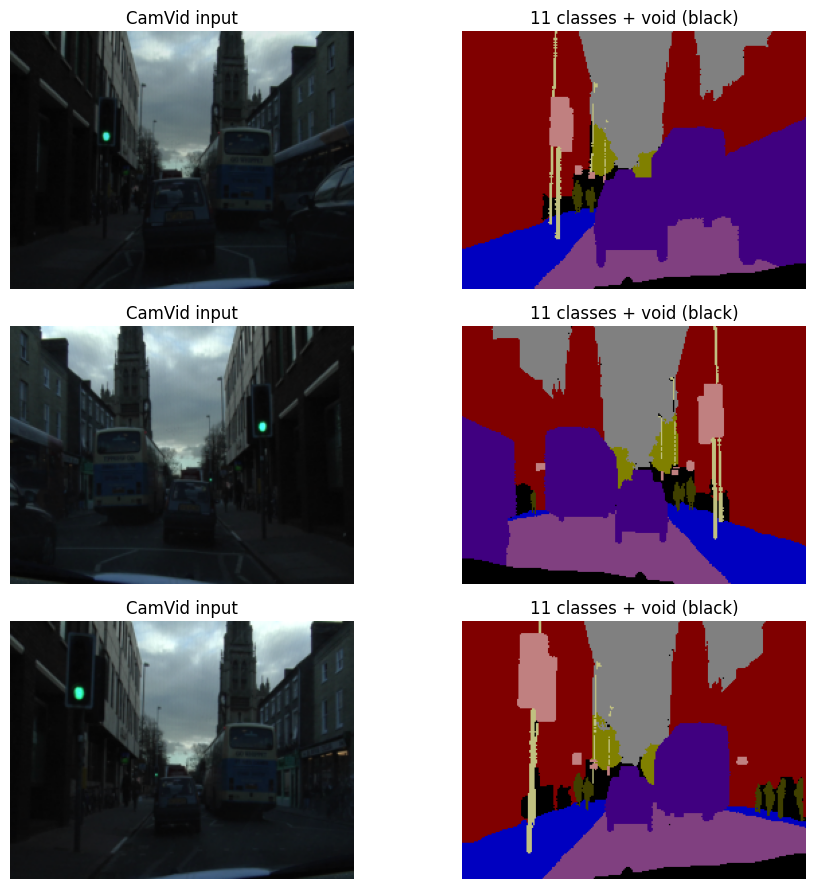

Input: (2, 3, 192, 256) | Output: (2, 11, 192, 256)
Parameter count: 1,962,795 | shape test PASSED


Train:   0%|          | 0/92 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/26 [00:10<?, ?it/s]

unet          epoch 01/20 | train 1.642 | val 1.411 | mIoU 0.146 | mDice 0.190


Train:   0%|          | 0/92 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/26 [00:00<?, ?it/s]

... (128 outputs left out)

Evaluate:   0%|          | 0/59 [00:00<?, ?it/s]

unet          | mIoU 0.3464 | mDice 0.4163 | pixelAcc 0.7939


Evaluate:   0%|          | 0/59 [00:00<?, ?it/s]

unet_no_skip  | mIoU 0.3460 | mDice 0.4183 | pixelAcc 0.7920


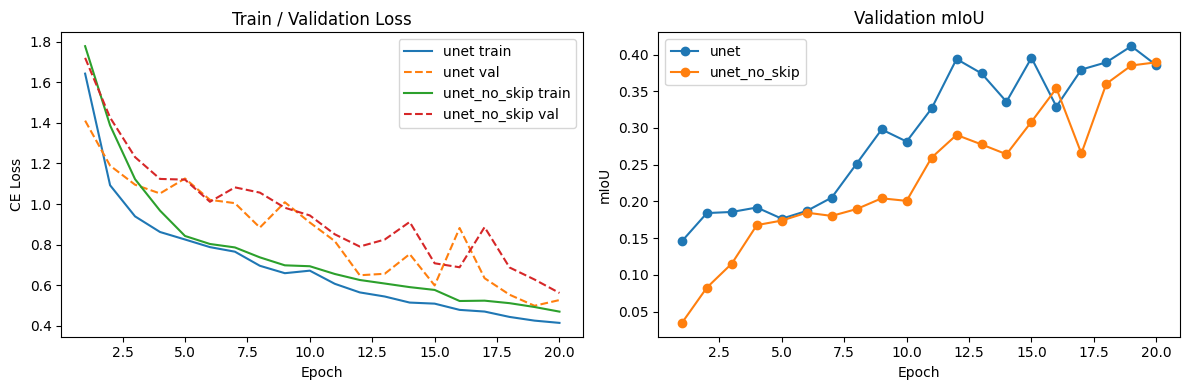

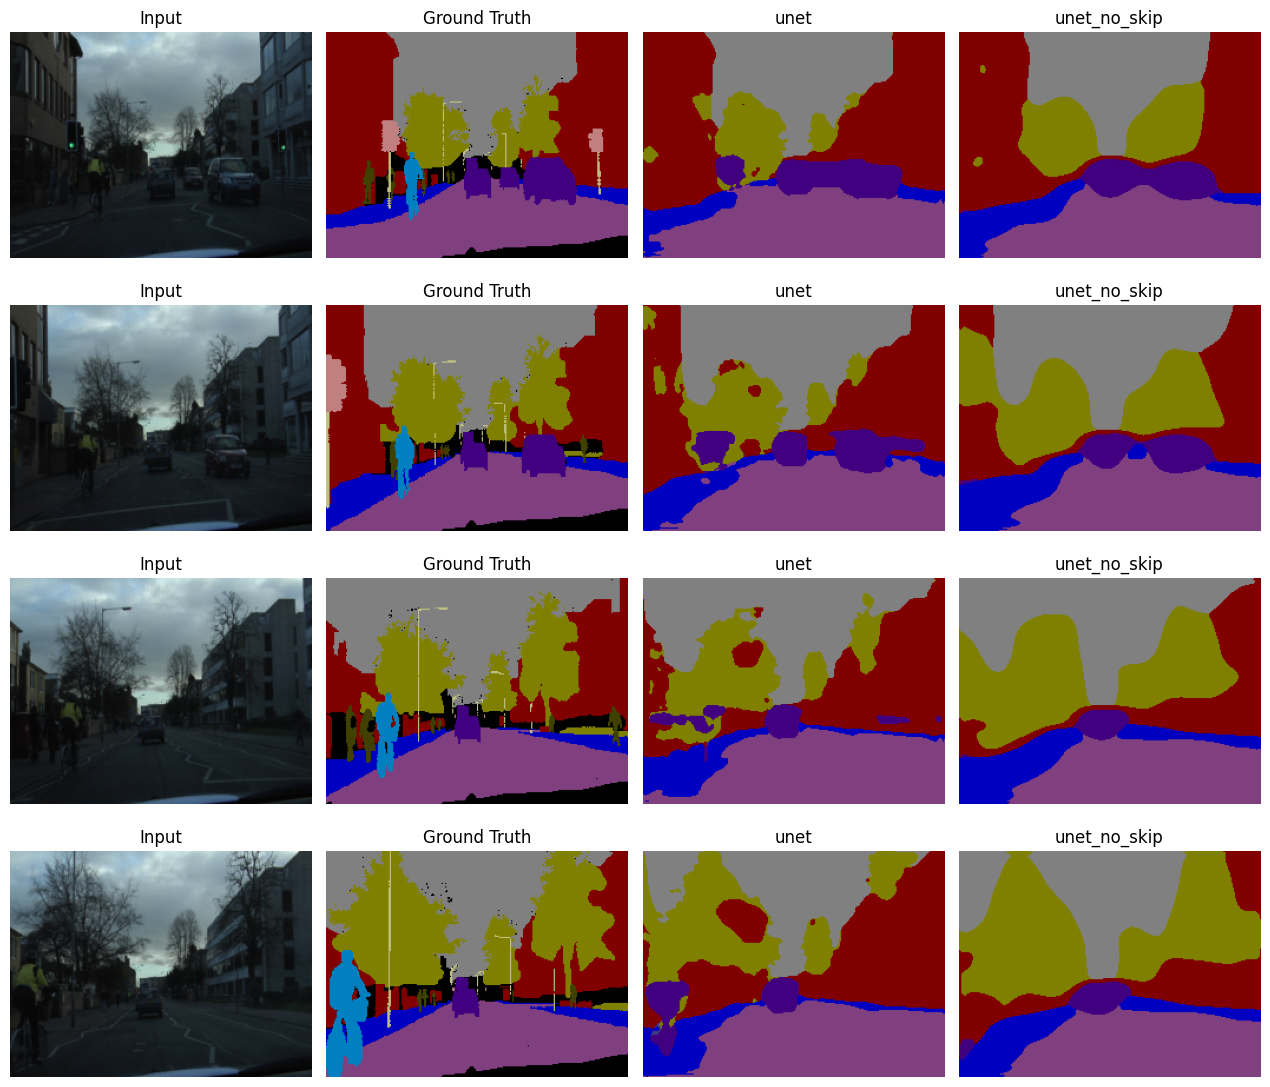

결과 저장: /content/camvid_unet_results


In [8]:
if __name__ == '__main__':
    models, histories, test_results = run_pipeline(CFG)